In [10]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import pandas as pd 
import scipy as sp 
import scipy.stats as sps
import astropy
from astropy.io import fits
from scipy.stats import poisson
import statsmodels as sm
from scipy.special import gammaln
from matplotlib.ticker import MultipleLocator, AutoMinorLocator


# colors 
# special plot params
plt.style.use('dark_background')
plt.rcParams['axes.facecolor'] = 'midnightblue'
plt.rcParams['figure.facecolor'] = "#060552"
plt.rcParams['axes.grid'] = 'True'
plt.rcParams['grid.color'] = 'steelblue'
plt.rcParams['grid.linewidth'] = 0.6
plt.rcParams['grid.alpha'] = 0.8
plt.rcParams['axes.edgecolor'] = 'white'
plt.rcParams['axes.linewidth'] = 0.5
plt.rcParams['legend.facecolor'] = "#060552"


# FUNCTIONS

def import_txts_get_arrays(folder_in_data_dir):  # this argument is a string
    '''
    This function: takes files from .txt in the data directory
    that holds the files that were output from the fits_to_txt_v3.py
    and takes those files, loads them in as numpy arrays, and then 
    creates an output of 2D wavelength arrays and flux arrays 
    
    input: 
    - exact folder where the data was originally (the "full" is included in the function) 
    output: 
    - 2 2D arrays 

    need to change per person: 
    - data_dir_path: wherever your general data folder is living 
    '''

    # data_dir_path = '/Users/leayamashiro/AnA_MSc/Observations/LaPalma_analysis/data/' 
    data_dir_path = '/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/data_LY/'
    files_glob = glob.glob(str(data_dir_path) + folder_in_data_dir + 'full/*.txt')
    wavelength_arrays = []
    flux_arrays = []
    spectra = []
    for file in files_glob: 
        spectrum = np.loadtxt(file)
        spectrum_wavelength = spectrum[:,0]
        spectrum_flux = spectrum[:,1]
        wavelength_arrays.append(spectrum_wavelength)
        flux_arrays.append(spectrum_flux)
        spectra.append(spectrum)
    return wavelength_arrays, flux_arrays, spectra


def get_txt_to_arrays_fullpath(path): 
    files_glob = glob.glob(str(path) + '/*.txt')
    wavelength_arrays = []
    flux_arrays = []
    spectra = []
    for file in files_glob: 
        spectrum = np.loadtxt(file)
        spectrum_wavelength = spectrum[:,0]
        spectrum_flux = spectrum[:,1]
        wavelength_arrays.append(spectrum_wavelength)
        flux_arrays.append(spectrum_flux)
        spectra.append(spectrum)
    return wavelength_arrays, flux_arrays, spectra


# this is using the output of import_txts_get_arrays as input.
# this is also just to check the length of the spectra
def check_length_all_spectra(wavelength_arrays): 
    for i in range(len(wavelength_arrays)): 
        wavelength_array = wavelength_arrays[i]
        print(len(wavelength_array))

# interpolate the spectra on the wavelength array from the first of three exposures
def interpolate_spectra(spectra):  
    # where spectra is an array of spectra that came out of the import .txt function
    wl_ref = spectra[0][:, 0] # reference wavelength array as just the first of the three (NOTE: we may change this) 
    interpolated_fluxes = [] # make empty list for all the interpolated fluxes 
    for i in range(len(spectra)): # iterate through the spectra 
        wl = spectra[i][:, 0] 
        flux = spectra[i][:, 1] 
        # interpolate on the reference axix
        aligned_flux = np.interp(x = wl_ref, 
                                xp = wl, 
                                fp = flux)
        # append to array for interpolated fluxes     
        interpolated_fluxes.append(aligned_flux)            
    return wl_ref, interpolated_fluxes

# get the median of interpolated spectra
def get_median_flux(interpolated_fluxes): 
    median_fluxes_interp = np.median(interpolated_fluxes, axis=0)
    return median_fluxes_interp

def get_median_spectra(wl_ref, interpolated_fluxes): 
    median_spectra = np.column_stack((wl_ref, interpolated_fluxes))
    return median_spectra

def interp_median_spectra_all(spectra): 
    wl_ref, interpolated_fluxes = interpolate_spectra(spectra)
    median_fluxes = get_median_flux(interpolated_fluxes)
    median_spectra = np.column_stack((wl_ref, median_fluxes))
    return median_spectra

def txts_to_median_spectra_total(path): 
    wavelength_arrays, flux_arrays, spectra = get_txt_to_arrays_fullpath(path)
    median_spectra = interp_median_spectra_all(spectra)
    return median_spectra

### Re-analyzing data from 10/5/2026


In [148]:
# name variables, run glob to get files

directory_path_2 = '/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/data_LY/data_051026_againfull/normalised/normed_2'
directory_path_3 = '/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/data_LY/data_051026_againfull/normalised/normed_3'
directory_path_4 = '/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/data_LY/data_051026_againfull/normalised/normed_4'
directory_path_5 = '/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/data_LY/data_051026_againfull/normalised/normed_5'
directory_path_6 = '/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/data_LY/data_051026_againfull/normalised/normed_6'
directory_path_7 = '/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/data_LY/data_051026_againfull/normalised/normed_7'
directory_path_8 = '/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/data_LY/data_051026_againfull/normalised/normed_8_symmpoints'


In [133]:
# directory_path_2 = '/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/data_LY/data_051026_againfull/normalised/normed_2'
# directory_path_3 = '/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/data_LY/data_051026_againfull/normalised/normed_3'

# wl_2, flux_2, spectra_2 = get_txt_to_arrays_fullpath(directory_path_2)
# wl_3, flux_3, spectra_3 = get_txt_to_arrays_fullpath(directory_path_3)
# wl_ref_2, interp_fluxes_2 = interpolate_spectra(spectra_2)
# wl_ref_3, interp_fluxes_3 = interpolate_spectra(spectra_3)
# median_2 = interp_median_spectra_all(spectra_2)
# median_3 = interp_median_spectra_all(spectra_3)
# median_spec_2 = txts_to_median_spectra_total(directory_path_2)
# median_spec_3 = txts_to_median_spectra_total(directory_path_3)
# median_2 == median_spec_2
# # proving function worked


In [ ]:
median_spec_2 = txts_to_median_spectra_total(directory_path_2)
median_spec_3 = txts_to_median_spectra_total(directory_path_3)
median_spec_4 = txts_to_median_spectra_total(directory_path_4)
median_spec_5 = txts_to_median_spectra_total(directory_path_5)
median_spec_6 = txts_to_median_spectra_total(directory_path_6)
median_spec_7 = txts_to_median_spectra_total(directory_path_7)
median_spec_8 = txts_to_median_spectra_total(directory_path_8)

#### FIND LIMITS OF INTEGRATION
(interactive plot not working)

Text(0.5, 0.98, 'Median 2 Test Integration Bounds')

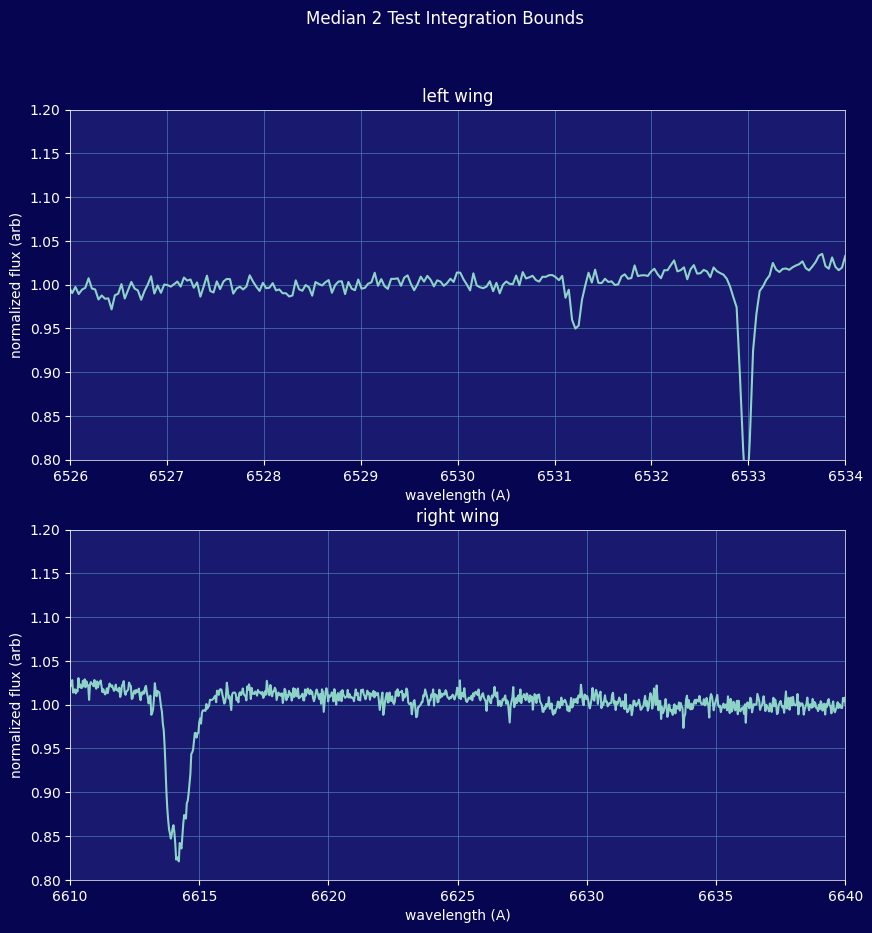

In [135]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2,1, figsize=(10,10))
ax[0].plot(median_spec_2[:,0], median_spec_2[:,1])
ax[0].set_xlim(6526, 6534)
ax[0].set_ylim(0.8, 1.2)
ax[0].set_title('left wing')
ax[0].set_xlabel('wavelength (A)')
ax[0].set_ylabel('normalized flux (arb)')

ax[1].plot(median_spec_2[:,0], median_spec_2[:,1])
ax[1].set_xlim(6610, 6640)
ax[1].set_ylim(0.8, 1.2)
ax[1].set_title('right wing')
ax[1].set_xlabel('wavelength (A)')
ax[1].set_ylabel('normalized flux (arb)')
plt.suptitle('Median 2 Test Integration Bounds')


So: left-side integration start at 6529, and end at 6632. 

In [136]:
import matplotlib.pyplot as plt # reloading to hopefully reset interactive...

h_alpha_left = 6529 # left bound
h_alpha_right = 6632 # right bound 

wl = median_spec_2[:,0] # wavelength array 
flux = median_spec_2[:,1] # flux array
 
line_mask = ( # create mask for the integration windows
    (wl >= h_alpha_left) &
    (wl <= h_alpha_right)
) 

line_wave = wl[line_mask] # cut wavelength array for integration
line_flux = flux[line_mask] # cut flux array for integration 

EW = np.trapezoid( # actually do the integral
    1.0 - line_flux,
    line_wave
)

print(np.abs(EW))

55.95401592896235


Text(0.5, 0.98, 'Median 3 Test Integration Bounds')

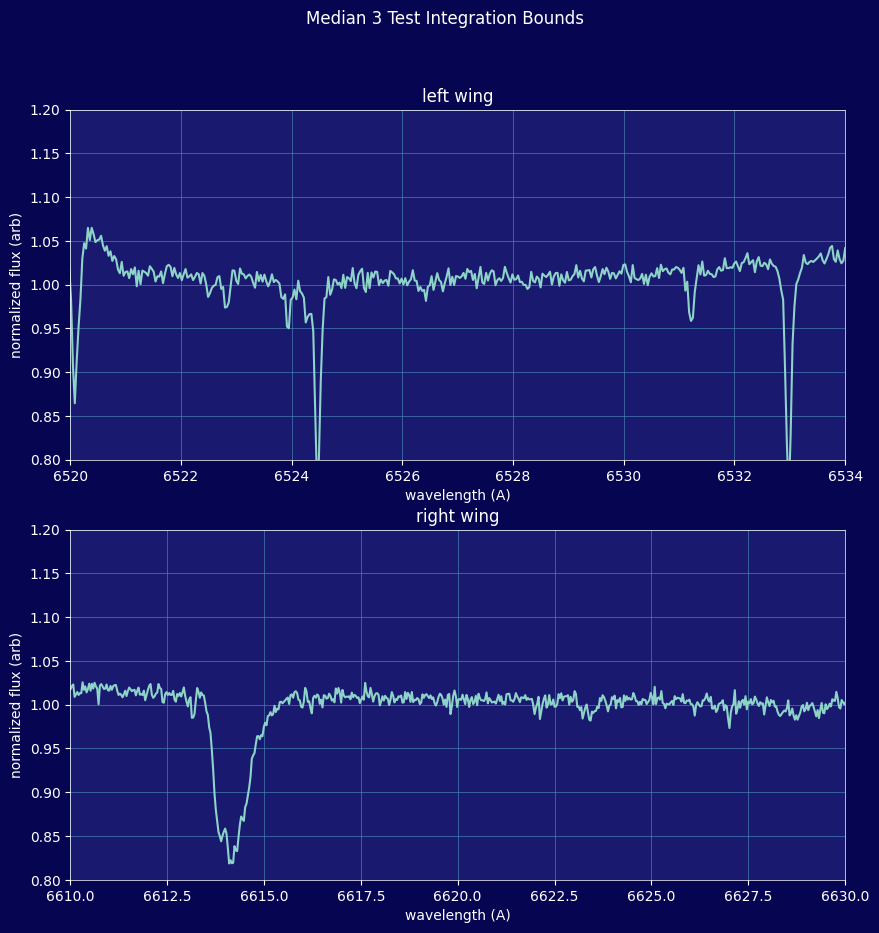

In [137]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2,1, figsize=(10,10))
ax[0].plot(median_spec_3[:,0], median_spec_3[:,1])
ax[0].set_xlim(6520, 6534)
ax[0].set_ylim(0.8, 1.2)
ax[0].set_title('left wing')
ax[0].set_xlabel('wavelength (A)')
ax[0].set_ylabel('normalized flux (arb)')

ax[1].plot(median_spec_3[:,0], median_spec_3[:,1])
ax[1].set_xlim(6610, 6630)
ax[1].set_ylim(0.8, 1.2)
ax[1].set_title('right wing')
ax[1].set_xlabel('wavelength (A)')
ax[1].set_ylabel('normalized flux (arb)')
plt.suptitle('Median 3 Test Integration Bounds')


Integration bounds: 6525, 6626

In [138]:
import matplotlib.pyplot as plt # reloading to hopefully reset interactive...

h_alpha_left = 6525 # left bound
h_alpha_right = 6612 # right bound 

wl = median_spec_3[:,0] # wavelength array 
flux = median_spec_3[:,1] # flux array
 
line_mask = ( # create mask for the integration windows
    (wl >= h_alpha_left) &
    (wl <= h_alpha_right)
) 

line_wave = wl[line_mask] # cut wavelength array for integration
line_flux = flux[line_mask] # cut flux array for integration 

EW = np.trapezoid( # actually do the integral
    1.0 - line_flux,
    line_wave
)

print('EW Estimate: ' + str(np.abs(EW)))

EW Estimate: 56.41900740442063


In [139]:
def EW_calculator(median_spectra, h_alpha_left, h_alpha_right): 
    
    wl = median_spectra[:,0] # wavelength array 
    flux = median_spectra[:,1] # flux array
    
    line_mask = ( # create mask for the integration windows
        (wl >= h_alpha_left) &
        (wl <= h_alpha_right)
    ) 

    line_wave = wl[line_mask] # cut wavelength array for integration
    line_flux = flux[line_mask] # cut flux array for integration 

    EW = np.trapezoid( # actually do the integral
        1.0 - line_flux,
        line_wave
    )
    print('EW Estimate: ' + str(np.abs(EW)))
    return EW

In [140]:
EW_norm3 = EW_calculator(median_spec_3, 6525, 6627)

EW Estimate: 56.33070170527143


Text(0.5, 0.98, 'Median 4 Test Integration Bounds')

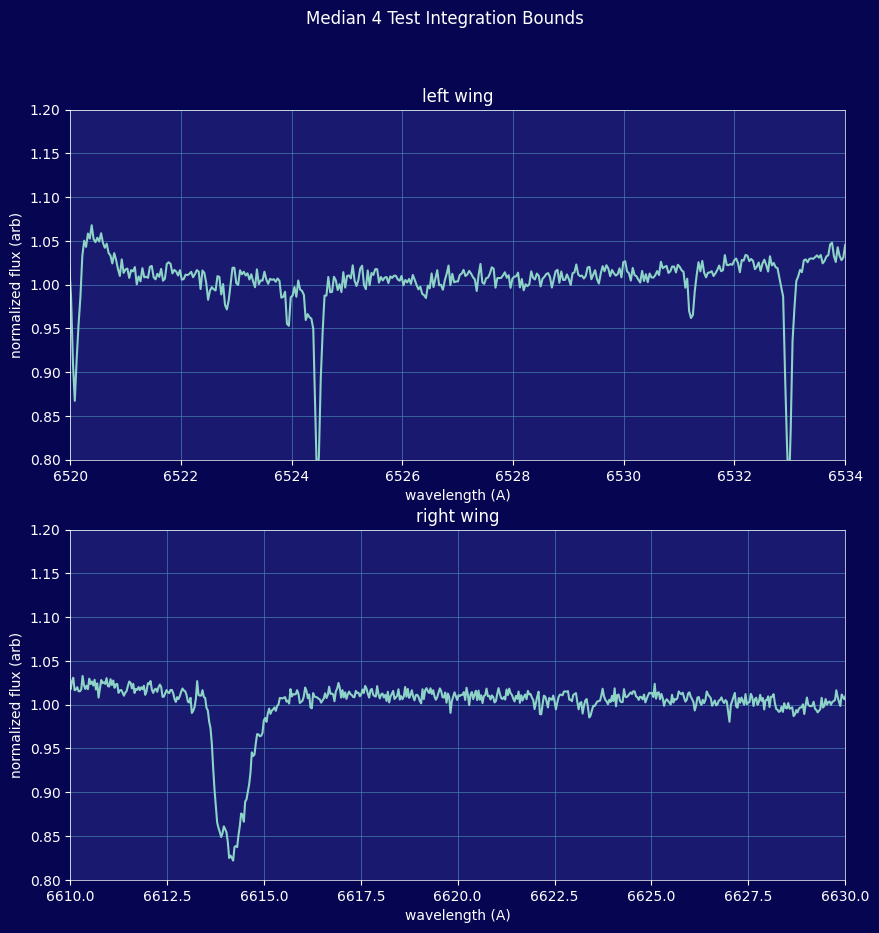

In [141]:
fig, ax = plt.subplots(2,1, figsize=(10,10))
ax[0].plot(median_spec_4[:,0], median_spec_4[:,1])
ax[0].set_xlim(6520, 6534)
ax[0].set_ylim(0.8, 1.2)
ax[0].set_title('left wing')
ax[0].set_xlabel('wavelength (A)')
ax[0].set_ylabel('normalized flux (arb)')

ax[1].plot(median_spec_4[:,0], median_spec_4[:,1])
ax[1].set_xlim(6610, 6630)
ax[1].set_ylim(0.8, 1.2)
ax[1].set_title('right wing')
ax[1].set_xlabel('wavelength (A)')
ax[1].set_ylabel('normalized flux (arb)')
plt.suptitle('Median 4 Test Integration Bounds')


Text(0.5, 0.98, 'Median 5 Test Integration Bounds')

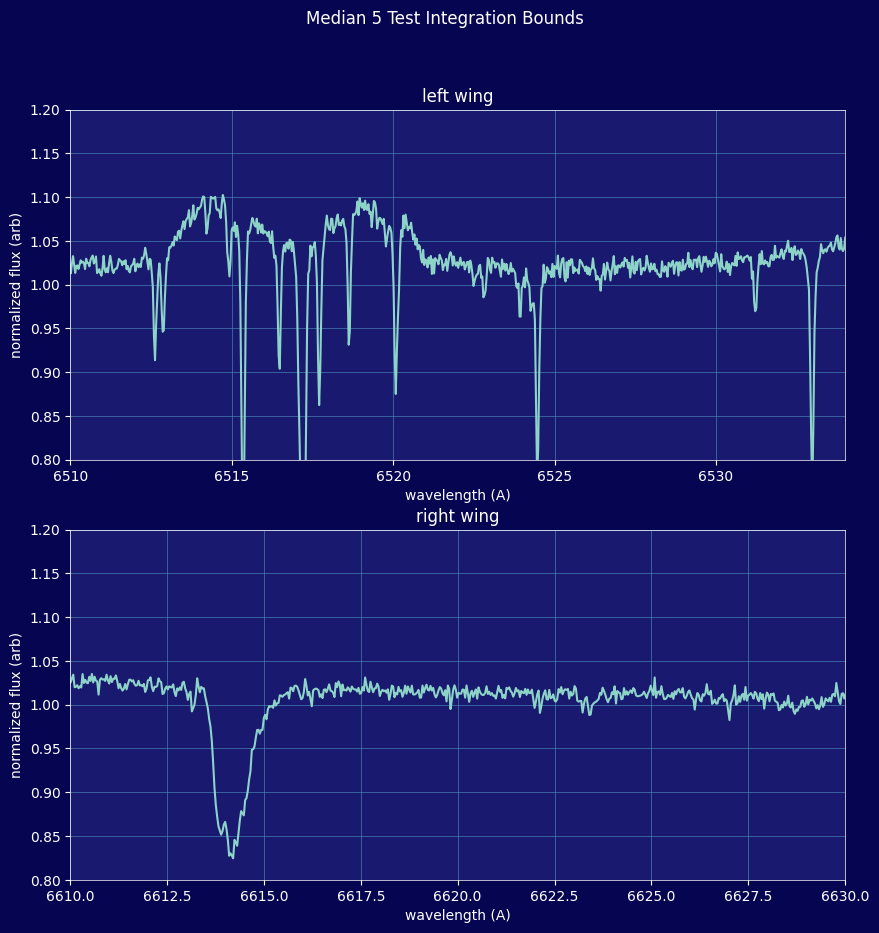

In [142]:
fig, ax = plt.subplots(2,1, figsize=(10,10))
ax[0].plot(median_spec_5[:,0], median_spec_5[:,1])
ax[0].set_xlim(6510, 6534)
ax[0].set_ylim(0.8, 1.2)
ax[0].set_title('left wing')
ax[0].set_xlabel('wavelength (A)')
ax[0].set_ylabel('normalized flux (arb)')

ax[1].plot(median_spec_5[:,0], median_spec_5[:,1])
ax[1].set_xlim(6610, 6630)
ax[1].set_ylim(0.8, 1.2)
ax[1].set_title('right wing')
ax[1].set_xlabel('wavelength (A)')
ax[1].set_ylabel('normalized flux (arb)')
plt.suptitle('Median 5 Test Integration Bounds')


OKay! So for this one, there were not enough points selected and it is clearly not properly normalized because those two bumps happen in a spot where they should return to the continuum and they are not. So need to use points closer in unfortunately to get a good continuum fit.

Text(0.5, 0.98, 'Median 6 Test Integration Bounds')

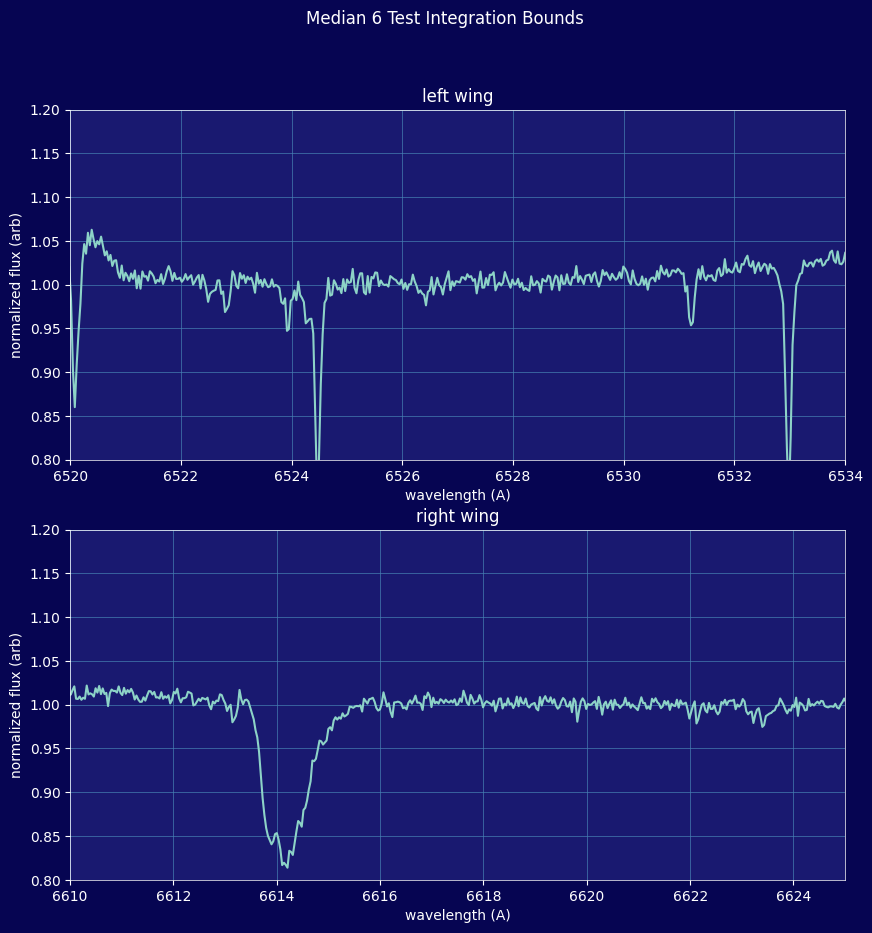

In [143]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2,1, figsize=(10,10))
ax[0].plot(median_spec_6[:,0], median_spec_6[:,1])
ax[0].set_xlim(6520, 6534)
ax[0].set_ylim(0.8, 1.2)
ax[0].set_title('left wing')
ax[0].set_xlabel('wavelength (A)')
ax[0].set_ylabel('normalized flux (arb)')

ax[1].plot(median_spec_6[:,0], median_spec_6[:,1])
ax[1].set_xlim(6610, 6625)
ax[1].set_ylim(0.8, 1.2)
ax[1].set_title('right wing')
ax[1].set_xlabel('wavelength (A)')
ax[1].set_ylabel('normalized flux (arb)')
plt.suptitle('Median 6 Test Integration Bounds')


Text(0.5, 0.98, 'Median 7 Test Integration Bounds')

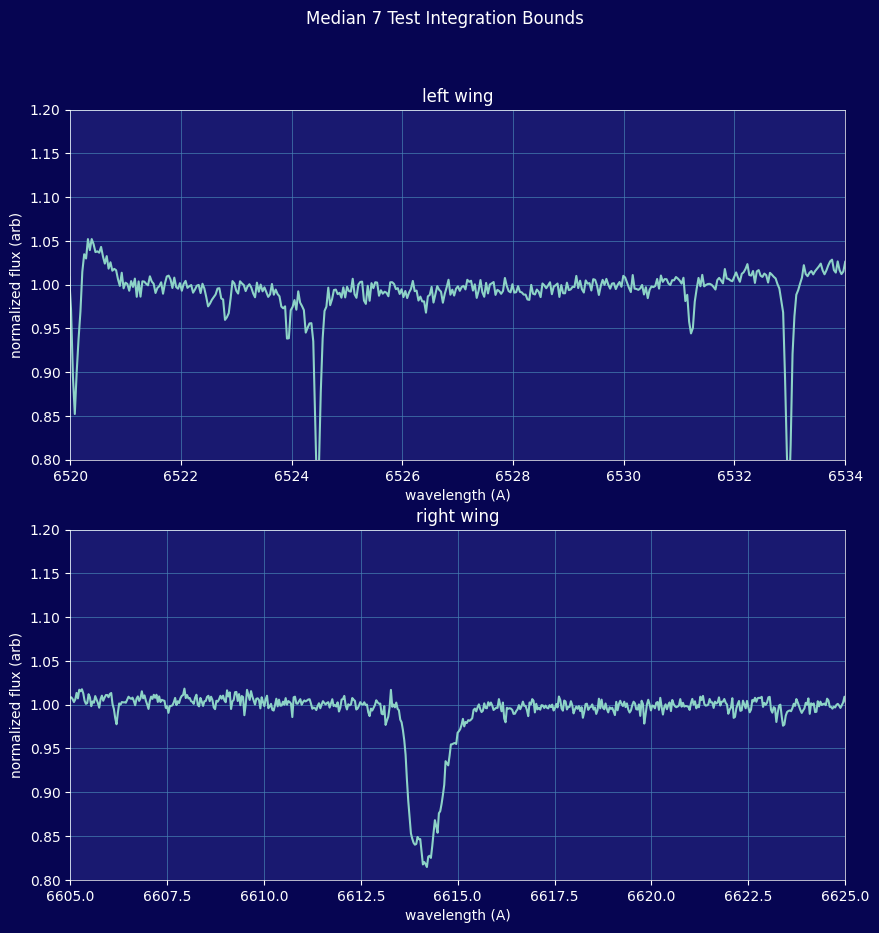

In [146]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2,1, figsize=(10,10))
ax[0].plot(median_spec_7[:,0], median_spec_7[:,1])
ax[0].set_xlim(6520, 6534)
ax[0].set_ylim(0.8, 1.2)
ax[0].set_title('left wing')
ax[0].set_xlabel('wavelength (A)')
ax[0].set_ylabel('normalized flux (arb)')

ax[1].plot(median_spec_7[:,0], median_spec_7[:,1])
ax[1].set_xlim(6605, 6625)
ax[1].set_ylim(0.8, 1.2)
ax[1].set_title('right wing')
ax[1].set_xlabel('wavelength (A)')
ax[1].set_ylabel('normalized flux (arb)')
plt.suptitle('Median 7 Test Integration Bounds')


Text(0.5, 0.98, 'Median 8 Test Integration Bounds')

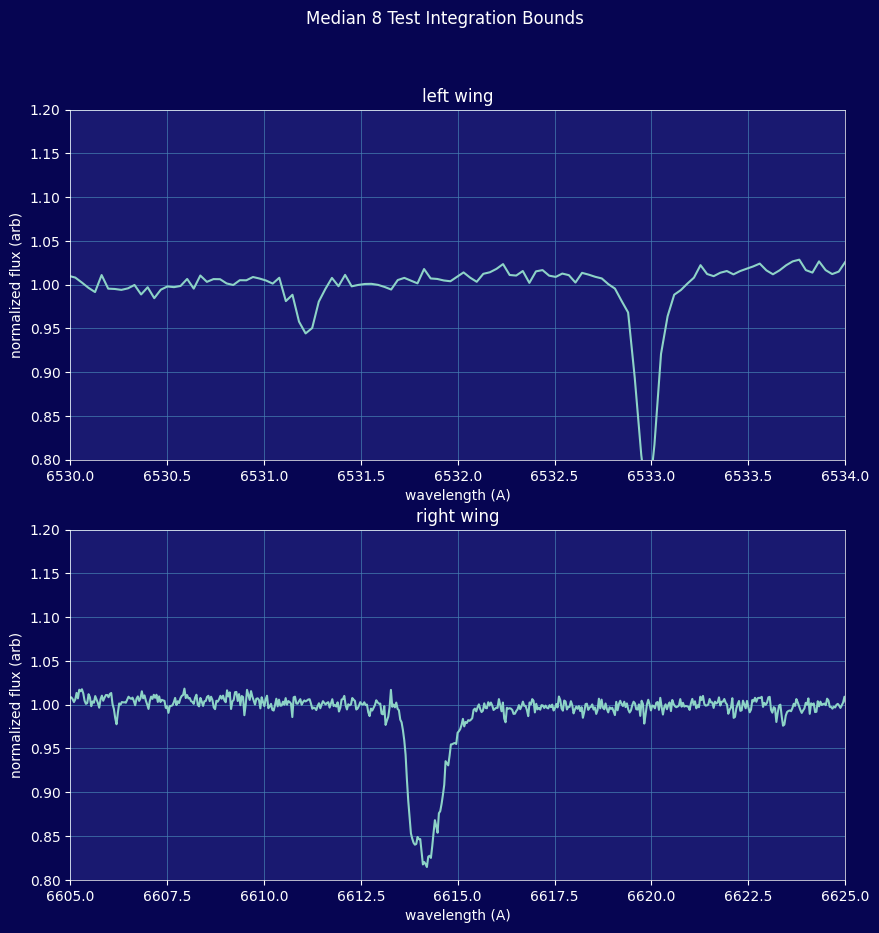

In [151]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2,1, figsize=(10,10))
ax[0].plot(median_spec_7[:,0], median_spec_7[:,1])
ax[0].set_xlim(6530, 6534)
ax[0].set_ylim(0.8, 1.2)
ax[0].set_title('left wing')
ax[0].set_xlabel('wavelength (A)')
ax[0].set_ylabel('normalized flux (arb)')

ax[1].plot(median_spec_7[:,0], median_spec_7[:,1])
ax[1].set_xlim(6605, 6625)
ax[1].set_ylim(0.8, 1.2)
ax[1].set_title('right wing')
ax[1].set_xlabel('wavelength (A)')
ax[1].set_ylabel('normalized flux (arb)')
plt.suptitle('Median 8 Test Integration Bounds')


In [83]:
EW_norm4_cut = EW_calculator(median_spec_4, 6525, 6612.5)
EW_norm4_whole = EW_calculator(median_spec_4, 6525, 6627.5)

EW Estimate: 56.802478799624254
EW Estimate: 56.75803108434664


In [84]:
EW_norm3_cut = EW_calculator(median_spec_3, 6525, 6612.5)
EW_norm3_whole = EW_calculator(median_spec_3, 6525, 6625)

EW Estimate: 56.42615064200169
EW Estimate: 56.32521464027417


In [ ]:
EW_norm2_cut = EW_calculator(median_spec_2, 6529, 6612.5)
EW_norm2_whole = EW_calculator(median_spec_2, 6529, 6632)

EW Estimate: 55.97139226918655
EW Estimate: 55.94362565102948


In [ ]:
EW_norm5_cut = EW_calculator(median_spec_5, 6525, 6612.5)
EW_norm5_whole = EW_calculator(median_spec_5, 6525, 6620)

EW Estimate: 57.897505681825386
EW Estimate: 57.83715522031014


In [129]:
EW_norm6_cut = EW_calculator(median_spec_6, 6528, 6612.5)
EW_norm6_whole = EW_calculator(median_spec_6, 6528, 6620)
EW_norm6_cut = EW_calculator(median_spec_6, 6525, 6612.5)
EW_norm6_whole = EW_calculator(median_spec_6, 6525, 6620)


EW Estimate: 55.77039805133794
EW Estimate: 55.61005645224295
EW Estimate: 55.77698289072029
EW Estimate: 55.6166412916253


In [147]:
EW_norm7_cut = EW_calculator(median_spec_7, 6530, 6612.5)


EW Estimate: 54.47161536307896


In [212]:
# EW_norm8 = EW_calculator(median_spec_8, 6530, 6612.5)
# EW_norm8 = EW_calculator(median_spec_8, 6525, 6630)

EW_norm8 = EW_calculator(median_spec_8, 6525, 6612.5)
EW_norm8 = EW_calculator(median_spec_8, 6525, 6630)
EW_norm8 = EW_calculator(median_spec_8, 6530, 6612.5)
EW_norm8 = EW_calculator(median_spec_8, 6530, 6630)

EW Estimate: 56.77103062489124
EW Estimate: 56.72833426696379
EW Estimate: 56.725147121466996
EW Estimate: 56.68245076353952


### Notes on Normalization/Line sensitivity

Pre-note: the choices for normalization were not based on symmetry, as symmetric arguments were first used but there proved to be differences in the length of the tails that led to over-normalization, thus selection of continuum points had to be done based on visual inspection of the results of normalization. The points selected here were already done trying to correct for this. 
Bounds for the Normalization (where there were no points selected around $H\alpha$) were: 
- '2': 6512.1 - 6635.0, width = 122.8999
- '3': 6503.97 - 6630.0, width = 126.0299
- '4': 6504.88 - 6635.03, width = 130.14999

For all three normalizations, there were variations in approximately where it seemed the $H\alpha$ returned to the continuum. Bounds for the H-alpha line under these conditions were (on visual inspection): 
- '2': (6529, 6632)
- '3': (6525, 6625)
- '4': (6525, 6627.5)

Normalization 2: 
- with ain aim to approximately end at 6510 right before the feature, the normalization ends further inward, 


In [95]:
6512.1 - 6635.0
6503.97 - 6630.0
6504.88 - 6635.03

-130.14999999999964

In [99]:
6512-6562.8

-50.80000000000018

In [100]:
6562.8-6635.0

-72.19999999999982

In [111]:
6630 - 6562

68

In [112]:
6562-68

6494

In [113]:
6562-6500

62

In [114]:
6562+62

6624

In [130]:
6562-6512.5

49.5

In [131]:
49.5 + 6562

6611.5

### 06/10/26

In [154]:
directory_path_0610_1 = '/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/data_LY/data_061026_againfull/normalised'

medspec_0610_1 = txts_to_median_spectra_total(directory_path_0610_1)

Text(0.5, 0.98, 'Median 8 Test Integration Bounds')

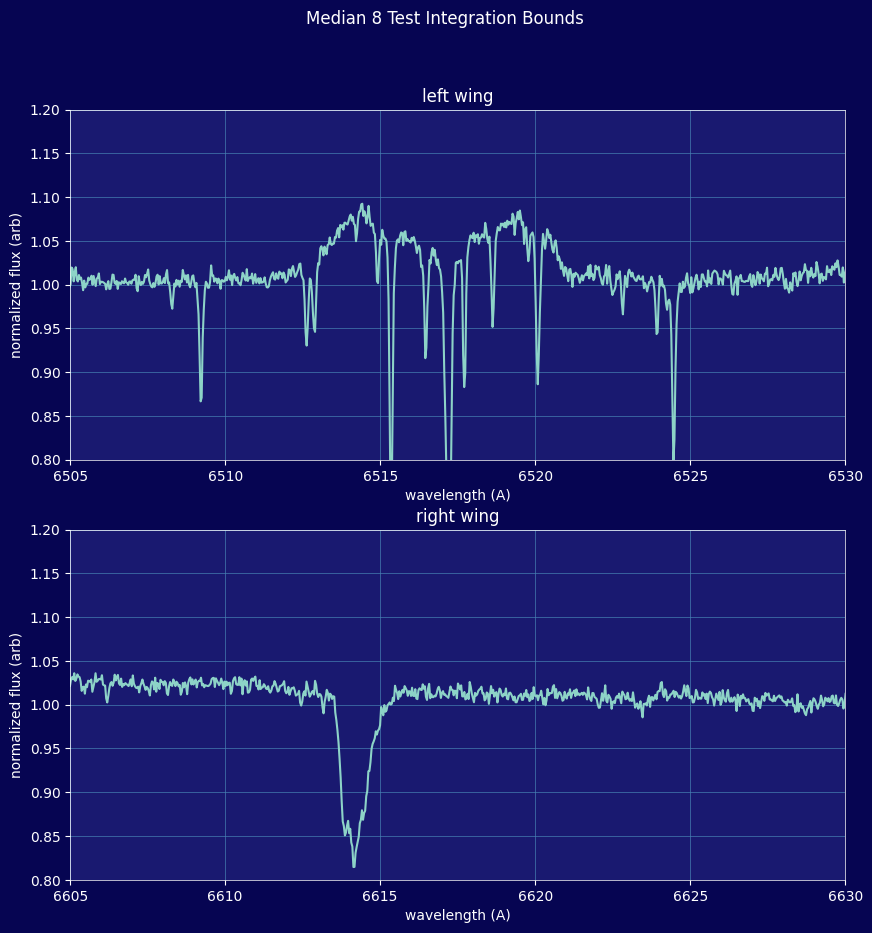

In [160]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2,1, figsize=(10,10))
ax[0].plot(medspec_0610_1[:,0], medspec_0610_1[:,1])
ax[0].set_xlim(6505, 6530)
ax[0].set_ylim(0.8, 1.2)
ax[0].set_title('left wing')
ax[0].set_xlabel('wavelength (A)')
ax[0].set_ylabel('normalized flux (arb)')

ax[1].plot(medspec_0610_1[:,0], medspec_0610_1[:,1])
ax[1].set_xlim(6605, 6630)
ax[1].set_ylim(0.8, 1.2)
ax[1].set_title('right wing')
ax[1].set_xlabel('wavelength (A)')
ax[1].set_ylabel('normalized flux (arb)')
plt.suptitle('Median 8 Test Integration Bounds')

In [167]:
EW_norm_0610 = EW_calculator(medspec_0610_1, 6525, 6612.5)
EW_norm_0610 = EW_calculator(medspec_0610_1, 6525, 6630)
EW_norm_0610 = EW_calculator(medspec_0610_1, 6530, 6612.5)
EW_norm_0610 = EW_calculator(medspec_0610_1, 6530, 6630)


EW Estimate: 56.93467118261706
EW Estimate: 56.925683957474256
EW Estimate: 56.89309362809762
EW Estimate: 56.884106402954814


### VERSUS CASARES

In [204]:
dir_path_casares1031 = '/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/analysis_2009_LY/091031_againfull/normalised/normed_1'
medspec_c_1031 = txts_to_median_spectra_total(dir_path_casares1031)
dir_path_casares1031_2 = '/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/analysis_2009_LY/091031_againfull/normalised/normed_2'
medspec_c_1031_2 = txts_to_median_spectra_total(dir_path_casares1031_2)
dir_path_casares1031_3 = '/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/analysis_2009_LY/091031_againfull/normalised/normed_3'
medspec_c_1031_3 = txts_to_median_spectra_total(dir_path_casares1031_3)
dir_path_casares1031_OT = '/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/analysis_2009_LY/091031_againfull/normalised/normed_old_temp'
medspec_c_1031_OT = txts_to_median_spectra_total(dir_path_casares1031_OT)

dir_path_casares1103_OT = '/Users/leayamashiro/AnA_MSc/Observations/git/lapalma_analysis/analysis_LY/analysis_2009_LY/091103_again/fitsfull/normalised'
medspec_c_1103_1 = txts_to_median_spectra_total(dir_path_casares1103_OT)

Text(0.5, 0.98, 'Median 8 Test Integration Bounds')

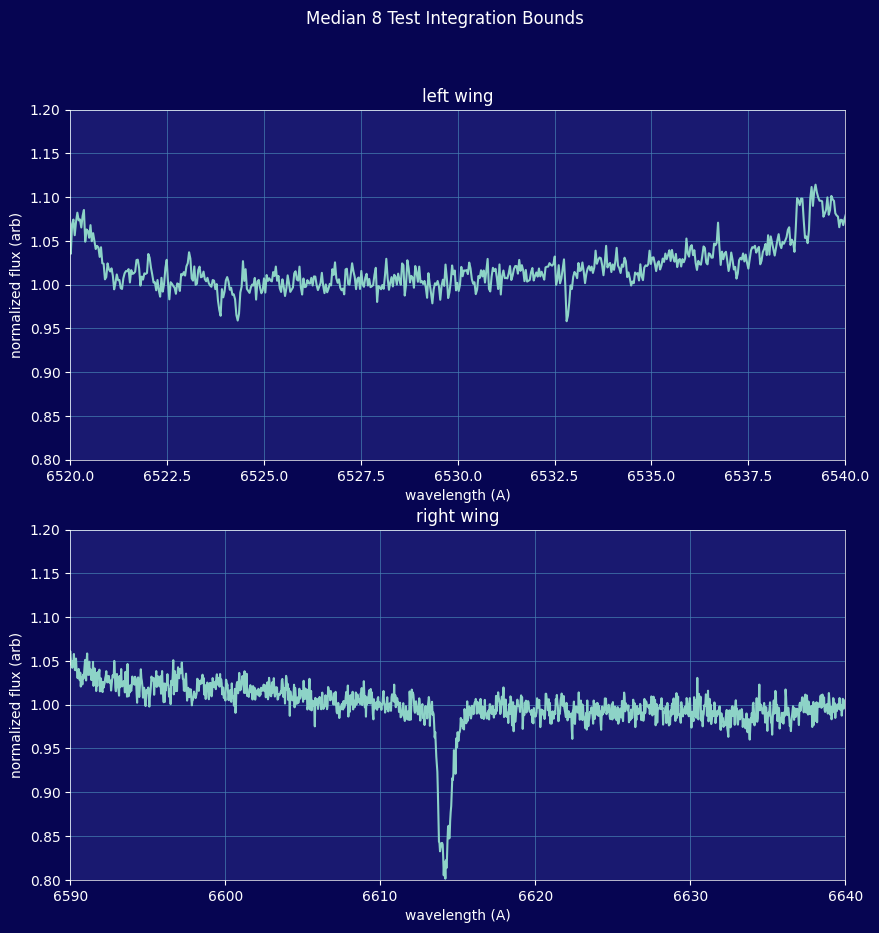

In [206]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(2,1, figsize=(10,10))
ax[0].plot(medspec_c_1103_1[:,0], medspec_c_1103_1[:,1])
ax[0].set_xlim(6520, 6540)
ax[0].set_ylim(0.8, 1.2)
ax[0].set_title('left wing')
ax[0].set_xlabel('wavelength (A)')
ax[0].set_ylabel('normalized flux (arb)')

ax[1].plot(medspec_c_1103_1[:,0], medspec_c_1103_1[:,1])
ax[1].set_xlim(6590, 6640)
ax[1].set_ylim(0.8, 1.2)
ax[1].set_title('right wing')
ax[1].set_xlabel('wavelength (A)')
ax[1].set_ylabel('normalized flux (arb)')
plt.suptitle('Median 8 Test Integration Bounds')

In [191]:
EW_norm_casares1031 = EW_calculator(medspec_c_1031, 6535, 6593)
EW_norm_casares1031 = EW_calculator(medspec_c_1031, 6525, 6630)
EW_norm_casares1031 = EW_calculator(medspec_c_1031, 6530, 6612.5)
EW_norm_casares1031 = EW_calculator(medspec_c_1031, 6530, 6630)

EW Estimate: 52.43610791170883
EW Estimate: 53.312577973669164
EW Estimate: 53.201832207685094
EW Estimate: 53.1902873648376


In [193]:
EW_norm_casares1031_2 = EW_calculator(medspec_c_1031_2, 6535, 6593)
EW_norm_casares1031_2 = EW_calculator(medspec_c_1031_2, 6525, 6630)
EW_norm_casares1031_2 = EW_calculator(medspec_c_1031_2, 6530, 6612.5)
EW_norm_casares1031_2 = EW_calculator(medspec_c_1031_2, 6530, 6630)

EW Estimate: 50.70746874086207
EW Estimate: 51.05308678237635
EW Estimate: 51.17180965963375
EW Estimate: 51.040469296544174


In [ ]:
EW_norm_casares1031_3 = EW_calculator(medspec_c_1031_3, 6530, 6593)
EW_norm_casares1031_3 = EW_calculator(medspec_c_1031_3, 6525, 6630)
EW_norm_casares1031_3 = EW_calculator(medspec_c_1031_3, 6530, 6612.5)
EW_norm_casares1031_3 = EW_calculator(medspec_c_1031_3, 6530, 6630)

EW Estimate: 50.200874136779234
EW Estimate: 50.23729155138522
EW Estimate: 50.496034990579304
EW Estimate: 50.23177800943377


In [203]:
EW_norm_casares1031_OT = EW_calculator(medspec_c_1031_OT, 6530, 6593)
EW_norm_casares1031_OT = EW_calculator(medspec_c_1031_OT, 6525, 6630)
EW_norm_casares1031_OT = EW_calculator(medspec_c_1031_OT, 6530, 6612.5)
EW_norm_casares1031_OT = EW_calculator(medspec_c_1031_OT, 6530, 6630)

EW Estimate: 49.76669629028325
EW Estimate: 49.729527167727845
EW Estimate: 49.88485185295669
EW Estimate: 49.72503684539042


In [211]:
EW_norm_casares1103_1 = EW_calculator(medspec_c_1103_1, 6525, 6630)


EW Estimate: 49.6031976947075


reusing our template on theirs:
- EW_norm_casares1031 = EW_calculator(medspec_c_1031, 6525, 6630)
- EW_norm_casares1031 = EW_calculator(medspec_c_1031, 6535, 6593)
- EW_norm_casares1031 = EW_calculator(medspec_c_1031, 6530, 6612.5)
- EW_norm_casares1031 = EW_calculator(medspec_c_1031, 6530, 6630)

- EW Estimate: 51.59702110534343
- EW Estimate: 52.24120457600479
- EW Estimate: 52.22719229935983
- EW Estimate: 52.175939694495746